In [2]:
import pandas as pd

# This is the exact path to your CSV file in your Internship_Project folder on the Desktop
file_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\24_mobile_app_usage.csv'

# Load the CSV file
df = pd.read_csv(file_path)

# Show the first 5 rows to prove it loaded successfully!
print("Success! Your CSV dataset has been loaded:")
display(df.head())

Success! Your CSV dataset has been loaded:


,Session_ID,User_ID,Session_Date,Feature_Used,Session_Duration_Mins,User_Rating,Device_Type,Age_Group,App_Version
0,SE000000,USR00198,2025-04-29 08:00:00,Video,39.1,4.6,Android,18-24,1.2
1,SE000001,USR00197,2026-03-02 02:00:00,Shopping,55.1,2.9,Android,18-24,2.0
2,SE000002,USR00126,2026-04-26 09:00:00,Video,40.7,4.4,iOS,35-44,1.2
3,SE000003,USR00398,2026-08-21 13:00:00,Search,14.6,3.3,Android,25-34,2.0
4,SE000004,USR00105,2025-10-09 13:00:00,Messaging,39.6,1.1,Android,55+,1.2


In [3]:
# 1. Check for missing values in every column
print("--- Missing Values ---")
missing_values = df.isnull().sum()
print(missing_values)

# 2. Check for completely duplicate rows
print("\n--- Duplicate Rows ---")
duplicate_rows = df.duplicated().sum()
print("Total duplicate rows:", duplicate_rows)

# 3. Check for duplicate Session IDs
print("\n--- Duplicate Session IDs ---")
duplicate_ids = df['Session_ID'].duplicated().sum()
print("Total duplicate Session IDs:", duplicate_ids)

--- Missing Values ---
Session_ID                0
User_ID                   0
Session_Date              0
Feature_Used              0
Session_Duration_Mins    25
User_Rating              26
Device_Type               0
Age_Group                 0
App_Version               0
dtype: int64

--- Duplicate Rows ---
Total duplicate rows: 15

--- Duplicate Session IDs ---
Total duplicate Session IDs: 15


In [4]:
# 1. Remove duplicate rows
df = df.drop_duplicates()
print("Rows remaining after dropping duplicates:", df.shape[0])

# 2. Fill missing values in Session_Duration_Mins with the median
median_duration = df['Session_Duration_Mins'].median()
df['Session_Duration_Mins'] = df['Session_Duration_Mins'].fillna(median_duration)

# 3. Fill missing values in User_Rating with the median
median_rating = df['User_Rating'].median()
df['User_Rating'] = df['User_Rating'].fillna(median_rating)

# 4. Verify that missing values are now 0
print("\n--- Missing Values After Cleaning ---")
print(df.isnull().sum())

Rows remaining after dropping duplicates: 1000

--- Missing Values After Cleaning ---
Session_ID               0
User_ID                  0
Session_Date             0
Feature_Used             0
Session_Duration_Mins    0
User_Rating              0
Device_Type              0
Age_Group                0
App_Version              0
dtype: int64


In [5]:
# 1. Find which app features are used the most
print("--- Feature Popularity ---")
feature_counts = df['Feature_Used'].value_counts()
print(feature_counts)

# 2. Compare Average Session Duration and User Rating by Device Type
print("\n--- Performance by Device Type ---")
device_summary = df.groupby('Device_Type')[['Session_Duration_Mins', 'User_Rating']].mean()
print(device_summary)

--- Feature Popularity ---
Feature_Used
Video        133
Messaging    131
Maps         130
Shopping     125
Profile      125
Search       124
Payments     117
News         115
Name: count, dtype: int64

--- Performance by Device Type ---
             Session_Duration_Mins  User_Rating
Device_Type                                    
Android                  61.206548     3.096726
Web                      59.634810     3.135443
iOS                      64.287356     3.025000


In [6]:
# 1. Convert Session_Date to actual datetime format so we can extract month and year
df['Session_Date'] = pd.to_datetime(df['Session_Date'])
df['Month'] = df['Session_Date'].dt.month

# 2. Group by Age Group to see session duration and ratings
print("--- Performance by Age Group ---")
age_summary = df.groupby('Age_Group')[['Session_Duration_Mins', 'User_Rating']].mean()
print(age_summary)

# 3. Find monthly session counts
print("\n--- Sessions per Month ---")
monthly_counts = df['Month'].value_counts().sort_index()
print(monthly_counts)

--- Performance by Age Group ---
           Session_Duration_Mins  User_Rating
Age_Group                                    
18-24                  62.364677     3.167662
25-34                  64.642718     2.990777
35-44                  59.779412     3.165196
45-54                  64.898515     3.044554
55+                    56.822460     3.050802

--- Sessions per Month ---
Month
1     101
2      89
3     111
4      93
5      91
6      84
7      85
8      89
9      81
10     87
11     46
12     43
Name: count, dtype: int64


In [7]:
import numpy as np

# 1. NumPy statistics for Session Duration
durations = df['Session_Duration_Mins'].values
print("--- Session Duration Statistics (NumPy) ---")
print(f"Mean: {np.mean(durations):.2f} minutes")
print(f"Median: {np.median(durations):.2f} minutes")
print(f"Standard Deviation: {np.std(durations):.2f}")

# 2. IQR (Interquartile Range) Method for Outliers in Session Duration
Q1 = np.percentile(durations, 25)
Q3 = np.percentile(durations, 75)
IQR = Q3 - Q1
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[(df['Session_Duration_Mins'] < lower_bound) | (df['Session_Duration_Mins'] > upper_bound)]
print(f"\n--- Outlier Detection ---")
print(f"Q1 (25th percentile): {Q1:.2f}")
print(f"Q3 (75th percentile): {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Number of unusually long/short sessions (outliers): {outliers.shape[0]}")

--- Session Duration Statistics (NumPy) ---
Mean: 61.78 minutes
Median: 62.30 minutes
Standard Deviation: 33.91

--- Outlier Detection ---
Q1 (25th percentile): 32.08
Q3 (75th percentile): 91.33
IQR: 59.25
Number of unusually long/short sessions (outliers): 0


Success! Cleaned CSV saved to your folder as 'cleaned_mobile_usage.csv'


C:\Users\HP\AppData\Local\Temp\ipykernel_8756\1206725288.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Feature_Used', order=df['Feature_Used'].value_counts().index, palette='viridis')


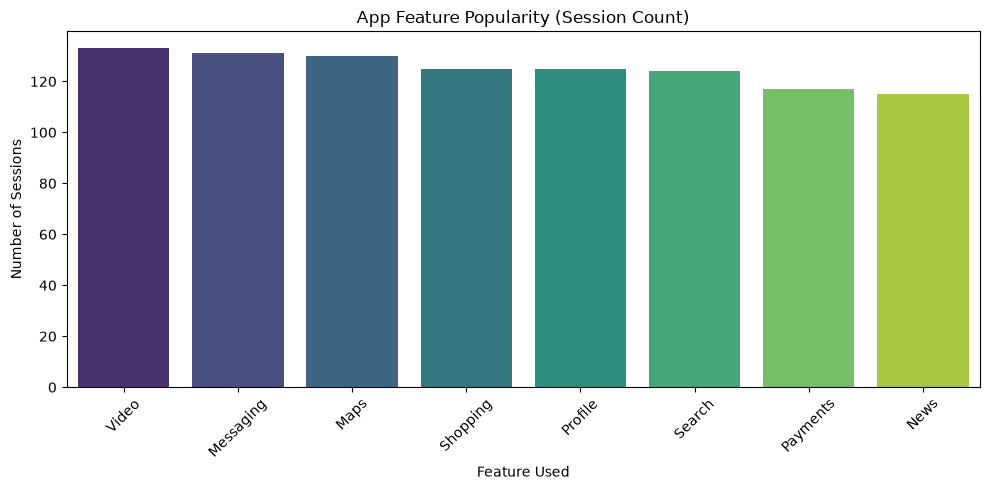

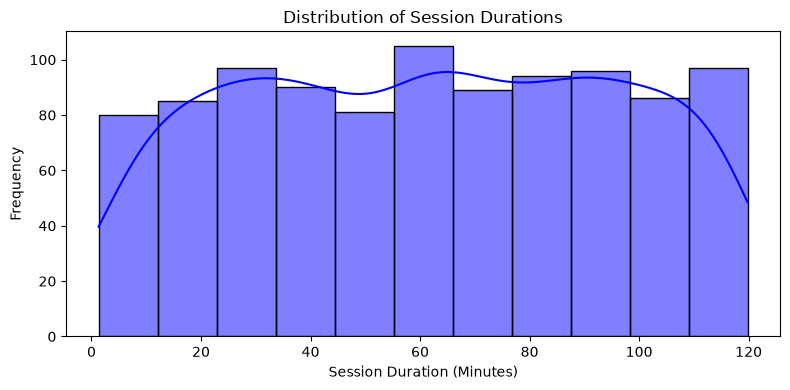

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Save your cleaned dataset as a new CSV file
output_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\cleaned_mobile_app_usage.csv'
df.to_csv(output_path, index=False)
print("Success! Cleaned CSV saved to your folder as 'cleaned_mobile_usage.csv'")

# 2. Plot Feature Popularity Bar Chart
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Feature_Used', order=df['Feature_Used'].value_counts().index, palette='viridis')
plt.title('App Feature Popularity (Session Count)')
plt.xlabel('Feature Used')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Plot Session Duration Distribution
plt.figure(figsize=(8, 4))
sns.histplot(df['Session_Duration_Mins'], kde=True, color='blue')
plt.title('Distribution of Session Durations')
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_8756\4211565519.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Feature_Used', order=df['Feature_Used'].value_counts().index, palette='viridis')


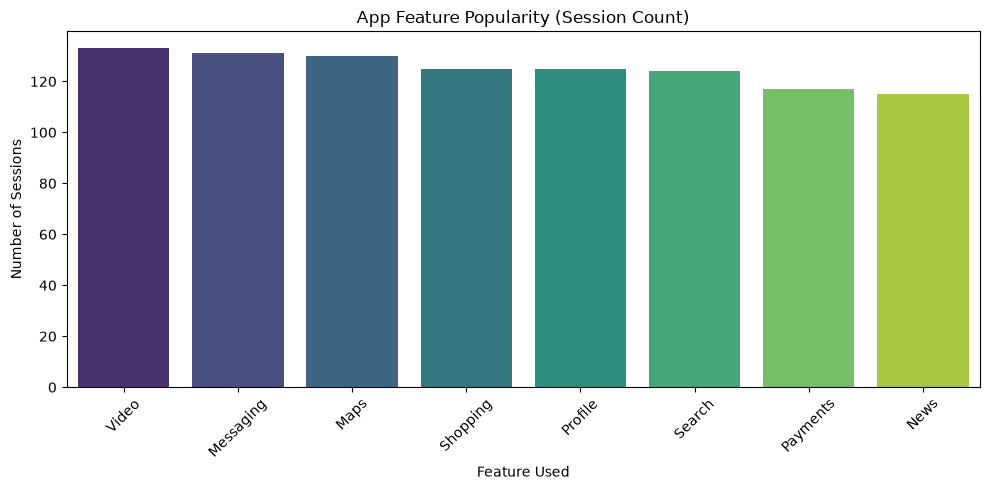

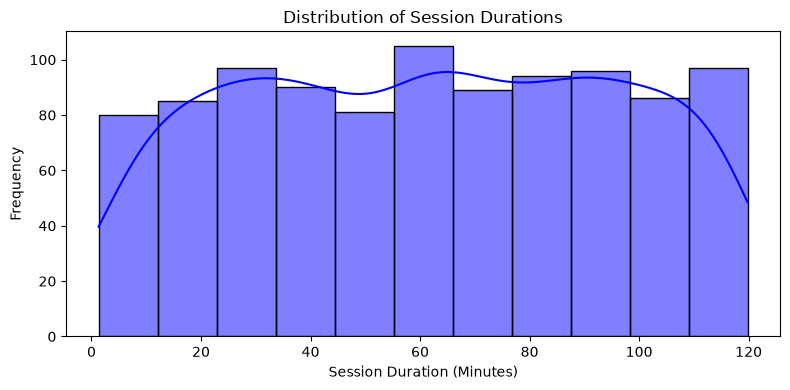

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Feature Popularity Chart
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Feature_Used', order=df['Feature_Used'].value_counts().index, palette='viridis')
plt.title('App Feature Popularity (Session Count)')
plt.xlabel('Feature Used')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.tight_layout()

# Save the chart as an image in your folder
plt.savefig('feature_popularity.png', dpi=300)
plt.show()

# 2. Session Duration Distribution Chart
plt.figure(figsize=(8, 4))
sns.histplot(df['Session_Duration_Mins'], kde=True, color='blue')
plt.title('Distribution of Session Durations')
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Frequency')
plt.tight_layout()

# Save the chart as an image in your folder
plt.savefig('session_duration_distribution.png', dpi=300)
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_8756\1463733203.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Feature_Used', order=df['Feature_Used'].value_counts().index, palette='viridis')


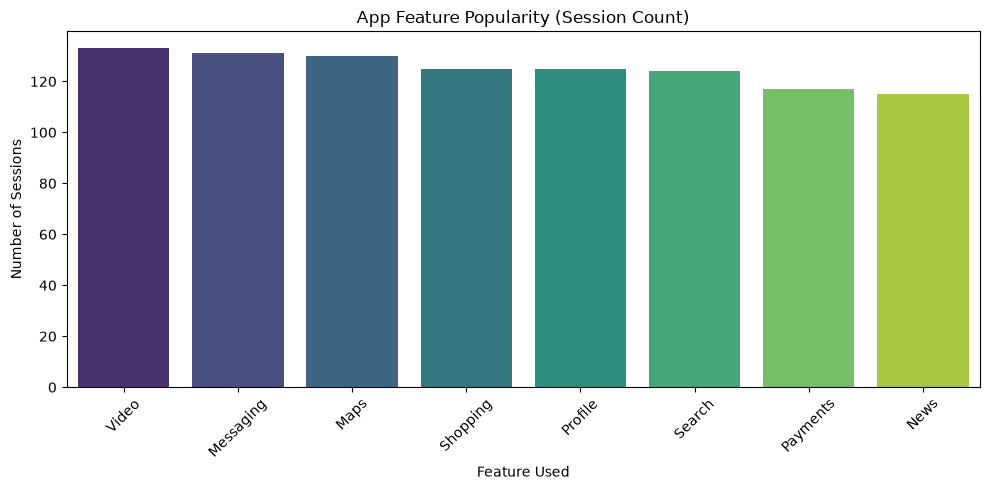

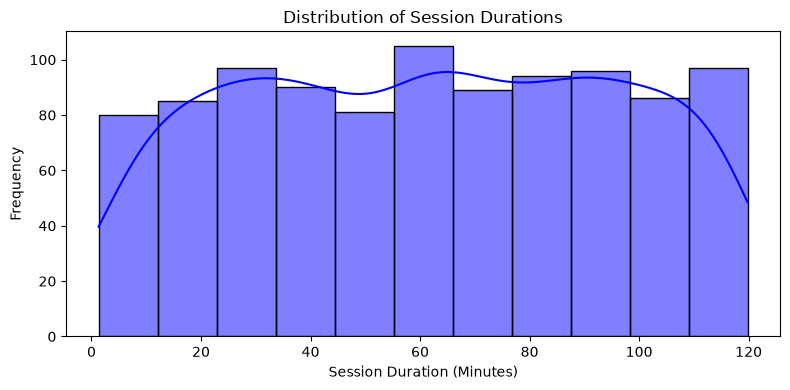

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Feature Popularity Chart
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Feature_Used', order=df['Feature_Used'].value_counts().index, palette='viridis')
plt.title('App Feature Popularity (Session Count)')
plt.xlabel('Feature Used')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.tight_layout()

# SAVE the chart as an image in your folder
plt.savefig(r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\feature_popularity.png', dpi=300)
plt.show()

# 2. Session Duration Distribution Chart
plt.figure(figsize=(8, 4))
sns.histplot(df['Session_Duration_Mins'], kde=True, color='blue')
plt.title('Distribution of Session Durations')
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Frequency')
plt.tight_layout()

# SAVE the chart as an image in your folder
plt.savefig(r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\session_duration_distribution.png', dpi=300)
plt.show()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. LOAD DATASET
# ==========================================
file_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\24_mobile_app_usage.csv'
df = pd.read_csv(file_path)

print("Initial Dataset Shape:", df.shape)
display(df.head())

# ==========================================
# 2. DATA AUDITING & CLEANING
# ==========================================
print("\n--- Missing Values Before Cleaning ---")
print(df.isnull().sum())
print("Total Duplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing values with median
df['Session_Duration_Mins'] = df['Session_Duration_Mins'].fillna(df['Session_Duration_Mins'].median())
df['User_Rating'] = df['User_Rating'].fillna(df['User_Rating'].median())

print("\n--- Missing Values After Cleaning ---")
print(df.isnull().sum())
print("Cleaned Dataset Shape:", df.shape)

# Save cleaned dataset
cleaned_output_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\cleaned_mobile_app_usage.csv'
df.to_csv(cleaned_output_path, index=False)
print(f"\nCleaned dataset saved successfully to: {cleaned_output_path}")

# ==========================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("\n--- Feature Popularity ---")
print(df['Feature_Used'].value_counts())

print("\n--- Performance by Device Type ---")
print(df.groupby('Device_Type')[['Session_Duration_Mins', 'User_Rating']].mean())

# Extract month from Session_Date
df['Session_Date'] = pd.to_datetime(df['Session_Date'])
df['Month'] = df['Session_Date'].dt.month

print("\n--- Performance by Age Group ---")
print(df.groupby('Age_Group')[['Session_Duration_Mins', 'User_Rating']].mean())

print("\n--- Sessions per Month ---")
print(df['Month'].value_counts().sort_index())

# ==========================================
# 4. STATISTICAL PROFILING & OUTLIER DETECTION
# ==========================================
durations = df['Session_Duration_Mins'].values
Q1 = np.percentile(durations, 25)
Q3 = np.percentile(durations, 75)
IQR = Q3 - Q1
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[(df['Session_Duration_Mins'] < lower_bound) | (df['Session_Duration_Mins'] > upper_bound)]

print("\n--- Session Duration Statistics ---")
print(f"Mean: {np.mean(durations):.2f} mins")
print(f"Median: {np.median(durations):.2f} mins")
print(f"Std Dev: {np.std(durations):.2f}")
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Outliers Detected: {outliers.shape[0]}")

# ==========================================
# 5. DATA VISUALIZATION & EXPORTING PLOTS
# ==========================================
# Chart 1: App Feature Popularity
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df, 
    x='Feature_Used', 
    hue='Feature_Used', 
    order=df['Feature_Used'].value_counts().index, 
    palette='viridis', 
    legend=False
)
plt.title('App Feature Popularity (Session Count)')
plt.xlabel('Feature Used')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\feature_popularity.png', dpi=300)
plt.show()

# Chart 2: Distribution of Session Durations
plt.figure(figsize=(8, 4))
sns.histplot(df['Session_Duration_Mins'], kde=True, color='blue')
plt.title('Distribution of Session Durations')
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\session_duration_distribution.png', dpi=300)
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\HP\\Desktop\\INTERNSHIP_PROJECT\\24_mobile_app_usage.csv'

In [2]:
import os

folder_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT'
print("Files in folder:", os.listdir(folder_path))

Files in folder: ['24_mobile_app_usage.xlsx', 'cleaned_mobile_app_usage.csv', 'feature_popularity.png', 'session_duration_distribution.png', 'SRS_Template (1).docx']


Available sheets: ['HCL PROJECT']
Initial Dataset Shape: (1015, 9)


,Session_ID,User_ID,Session_Date,Feature_Used,Session_Duration_Mins,User_Rating,Device_Type,Age_Group,App_Version
0,SE000000,USR00198,2025-04-29 08:00:00,Video,39.1,4.6,Android,18-24,1.2
1,SE000001,USR00197,2026-03-02 02:00:00,Shopping,55.1,2.9,Android,18-24,2.0
2,SE000002,USR00126,2026-04-26 09:00:00,Video,40.7,4.4,iOS,35-44,1.2
3,SE000003,USR00398,2026-08-21 13:00:00,Search,14.6,3.3,Android,25-34,2.0
4,SE000004,USR00105,2025-10-09 13:00:00,Messaging,39.6,1.1,Android,55+,1.2



--- Missing Values Before Cleaning ---
Session_ID                0
User_ID                   0
Session_Date              0
Feature_Used              0
Session_Duration_Mins    25
User_Rating              26
Device_Type               0
Age_Group                 0
App_Version               0
dtype: int64
Total Duplicate Rows: 15

--- Missing Values After Cleaning ---
Session_ID               0
User_ID                  0
Session_Date             0
Feature_Used             0
Session_Duration_Mins    0
User_Rating              0
Device_Type              0
Age_Group                0
App_Version              0
dtype: int64
Cleaned Dataset Shape: (1000, 9)

Cleaned dataset saved successfully to: C:\Users\HP\Desktop\INTERNSHIP_PROJECT\cleaned_mobile_app_usage.csv

--- Feature Popularity ---
Feature_Used
Video        133
Messaging    131
Maps         130
Shopping     125
Profile      125
Search       124
Payments     117
News         115
Name: count, dtype: int64

--- Performance by Device Type

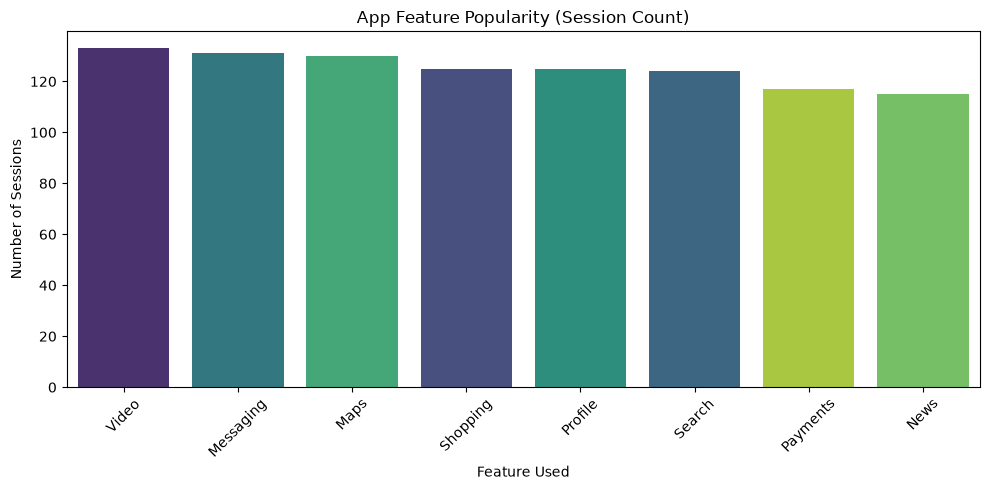

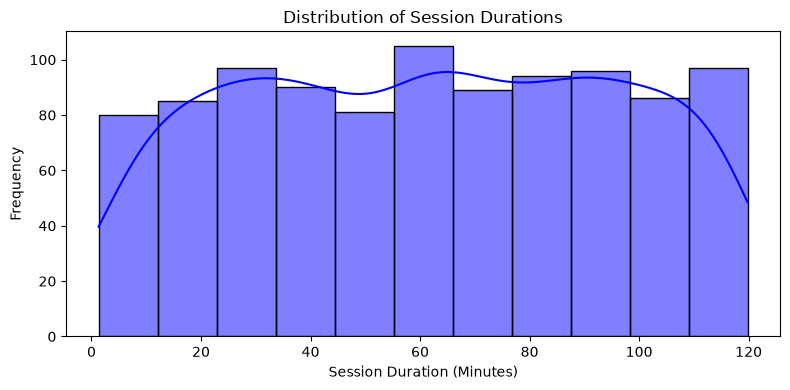

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. LOAD DATASET (EXCEL FILE)
# ==========================================
file_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\24_mobile_app_usage.xlsx'

# Automatically read the first sheet of the Excel file
excel_file = pd.ExcelFile(file_path)
print("Available sheets:", excel_file.sheet_names)
df = pd.read_excel(file_path, sheet_name=excel_file.sheet_names[0])

print("Initial Dataset Shape:", df.shape)
display(df.head())

# ==========================================
# 2. DATA AUDITING & CLEANING
# ==========================================
print("\n--- Missing Values Before Cleaning ---")
print(df.isnull().sum())
print("Total Duplicate Rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing values with median
df['Session_Duration_Mins'] = df['Session_Duration_Mins'].fillna(df['Session_Duration_Mins'].median())
df['User_Rating'] = df['User_Rating'].fillna(df['User_Rating'].median())

print("\n--- Missing Values After Cleaning ---")
print(df.isnull().sum())
print("Cleaned Dataset Shape:", df.shape)

# Save cleaned dataset
cleaned_output_path = r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\cleaned_mobile_app_usage.csv'
df.to_csv(cleaned_output_path, index=False)
print(f"\nCleaned dataset saved successfully to: {cleaned_output_path}")

# ==========================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
print("\n--- Feature Popularity ---")
print(df['Feature_Used'].value_counts())

print("\n--- Performance by Device Type ---")
print(df.groupby('Device_Type')[['Session_Duration_Mins', 'User_Rating']].mean())

# Extract month from Session_Date
df['Session_Date'] = pd.to_datetime(df['Session_Date'])
df['Month'] = df['Session_Date'].dt.month

print("\n--- Performance by Age Group ---")
print(df.groupby('Age_Group')[['Session_Duration_Mins', 'User_Rating']].mean())

print("\n--- Sessions per Month ---")
print(df['Month'].value_counts().sort_index())

# ==========================================
# 4. STATISTICAL PROFILING & OUTLIER DETECTION
# ==========================================
durations = df['Session_Duration_Mins'].values
Q1 = np.percentile(durations, 25)
Q3 = np.percentile(durations, 75)
IQR = Q3 - Q1
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = df[(df['Session_Duration_Mins'] < lower_bound) | (df['Session_Duration_Mins'] > upper_bound)]

print("\n--- Session Duration Statistics ---")
print(f"Mean: {np.mean(durations):.2f} mins")
print(f"Median: {np.median(durations):.2f} mins")
print(f"Std Dev: {np.std(durations):.2f}")
print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
print(f"Outliers Detected: {outliers.shape[0]}")

# ==========================================
# 5. DATA VISUALIZATION & EXPORTING PLOTS
# ==========================================
# Chart 1: App Feature Popularity
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df, 
    x='Feature_Used', 
    hue='Feature_Used', 
    order=df['Feature_Used'].value_counts().index, 
    palette='viridis', 
    legend=False
)
plt.title('App Feature Popularity (Session Count)')
plt.xlabel('Feature Used')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\feature_popularity.png', dpi=300)
plt.show()

# Chart 2: Distribution of Session Durations
plt.figure(figsize=(8, 4))
sns.histplot(df['Session_Duration_Mins'], kde=True, color='blue')
plt.title('Distribution of Session Durations')
plt.xlabel('Session Duration (Minutes)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(r'C:\Users\HP\Desktop\INTERNSHIP_PROJECT\session_duration_distribution.png', dpi=300)
plt.show()

In [1]:
import os
print(os.getcwd())

C:\Users\HP
